In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [3]:
data_path = path + '/diabetes_prediction_dataset.csv'

In [ ]:
from EDA import eda_process
from preprocessing import preprocess
import pandas as pd

df1, df2 = eda_process(data_path, target_col='diabetes')

processed_results = preprocess(df1, df2, target_column='diabetes', random_state=42)

X_train = processed_results['Dataset_2']['X_train']
y_train = processed_results['Dataset_2']['y_train']
X_val = processed_results['Dataset_2']['X_val']
y_val = processed_results['Dataset_2']['y_val']
X_test = processed_results['Dataset_2']['X_test']
y_test = processed_results['Dataset_2']['y_test']

print("Kích thước tập Train (đã qua SMOTE):", X_train.shape)
print("Kích thước tập Test:", X_test.shape)

In [5]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

rlr_base = LogisticRegression(penalty='l2', solver='lbfgs', random_state=42)

param_grid = {
    'C': [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


# Thiết lập GridSearchCV
grid_search = GridSearchCV(
    estimator=rlr_base,
    param_grid=param_grid,
    cv=skf,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print(f"- Siêu tham số (C): {grid_search.best_params_['C']}")
print(f"- Hệ số Lambda tương ứng: {1 / grid_search.best_params_['C']}")
print(f"- Điểm F1 (Cross-Validation): {grid_search.best_score_}")

Fitting 5 folds for each of 9 candidates, totalling 45 fits
- Siêu tham số (C): 10.0
- Hệ số Lambda tương ứng: 0.1
- Điểm F1 (Cross-Validation): 0.8946602549834145


  [LR-Manual] Dataset_2 Done! Final Loss: 0.2402


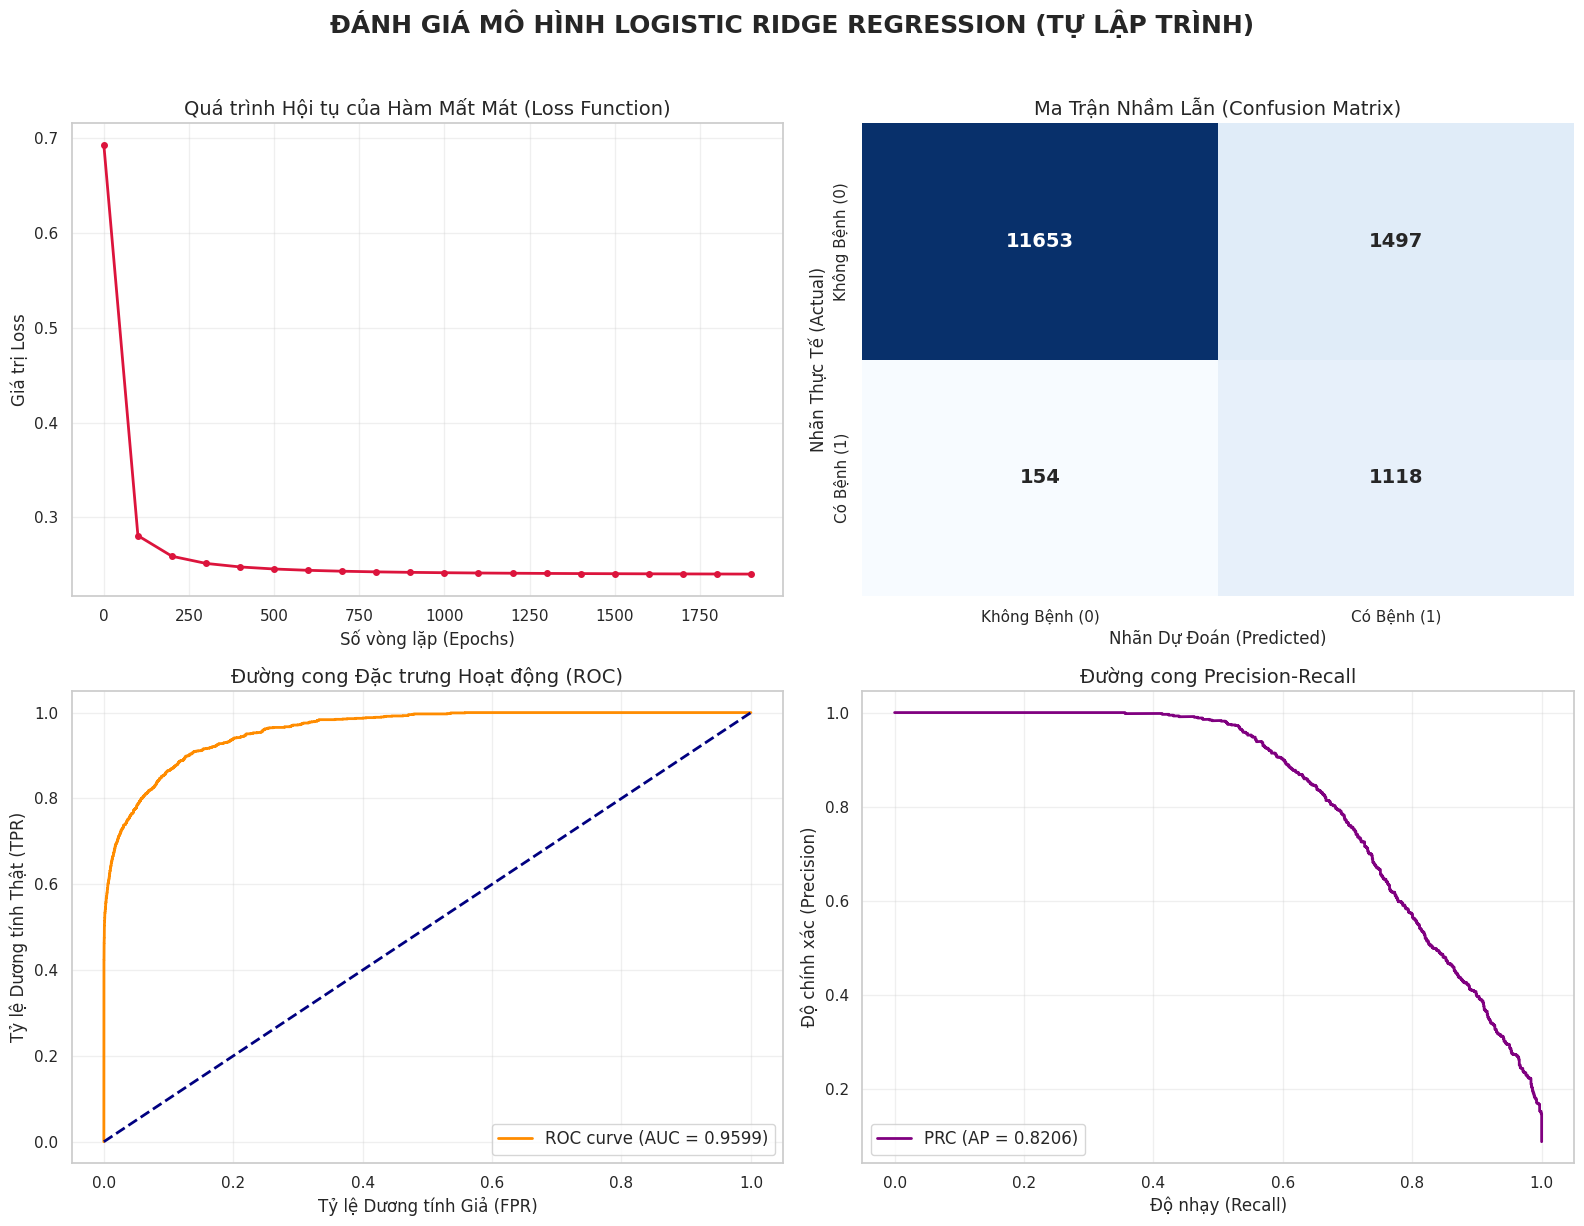

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import StandardScaler
from LogisticRegression import LogisticRegressionManual


lr_manual = LogisticRegressionManual(learning_rate=0.1, epochs=2000, lambda_param=0.1, threshold=0.5)

lr_manual.fit(X_train, y_train, ds_name="Dataset_2")

y_pred_manual = lr_manual.predict(X_test)
y_proba_manual = lr_manual.predict_proba(X_test)
y_true = y_test.values

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('ĐÁNH GIÁ MÔ HÌNH LOGISTIC RIDGE REGRESSION (TỰ LẬP TRÌNH)', fontsize=18, fontweight='bold', y=1.02)

# LOSS HISTORY
epochs_recorded = [i * 100 for i in range(len(lr_manual.loss_history))] # Vì lúc code bạn em lưu loss mỗi 100 epoch
axes[0, 0].plot(epochs_recorded, lr_manual.loss_history, color='crimson', lw=2, marker='o', markersize=4)
axes[0, 0].set_title('Quá trình Hội tụ của Hàm Mất Mát (Loss Function)', fontsize=14)
axes[0, 0].set_xlabel('Số vòng lặp (Epochs)', fontsize=12)
axes[0, 0].set_ylabel('Giá trị Loss', fontsize=12)
axes[0, 0].grid(alpha=0.3)

# MA TRẬN NHẦM LẪN
cm = confusion_matrix(y_true, y_pred_manual)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 1], annot_kws={"size": 14, "weight": "bold"}, cbar=False)
axes[0, 1].set_title('Ma Trận Nhầm Lẫn (Confusion Matrix)', fontsize=14)
axes[0, 1].set_xlabel('Nhãn Dự Đoán (Predicted)', fontsize=12)
axes[0, 1].set_ylabel('Nhãn Thực Tế (Actual)', fontsize=12)
axes[0, 1].xaxis.set_ticklabels(['Không Bệnh (0)', 'Có Bệnh (1)'])
axes[0, 1].yaxis.set_ticklabels(['Không Bệnh (0)', 'Có Bệnh (1)'])

# ĐƯỜNG CONG ROC
fpr, tpr, _ = roc_curve(y_true, y_proba_manual)
roc_auc = auc(fpr, tpr)
axes[1, 0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[1, 0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1, 0].set_title('Đường cong Đặc trưng Hoạt động (ROC)', fontsize=14)
axes[1, 0].set_xlabel('Tỷ lệ Dương tính Giả (FPR)', fontsize=12)
axes[1, 0].set_ylabel('Tỷ lệ Dương tính Thật (TPR)', fontsize=12)
axes[1, 0].legend(loc="lower right", fontsize=12)
axes[1, 0].grid(alpha=0.3)

# ĐƯỜNG CONG PRECISION-RECALL (PRC) 
precision, recall, _ = precision_recall_curve(y_true, y_proba_manual)
pr_auc = average_precision_score(y_true, y_proba_manual)
axes[1, 1].plot(recall, precision, color='purple', lw=2, label=f'PRC (AP = {pr_auc:.4f})')
axes[1, 1].set_title('Đường cong Precision-Recall', fontsize=14)
axes[1, 1].set_xlabel('Độ nhạy (Recall)', fontsize=12)
axes[1, 1].set_ylabel('Độ chính xác (Precision)', fontsize=12)
axes[1, 1].legend(loc="lower left", fontsize=12)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()